# UK wind forecast accuracy — January 2026 decisions

This notebook answers the six questions in PRD §11. It imports the **same** `selection.py` and `metrics.py`
as the API, so every number here matches the app.

* **Decision window:** decisions made 1–31 Jan 2026, so delivery days 2 Jan – 1 Feb 2026.
* **Default cutoff:** 09:00 UK time on D-1, just before the earliest GB day-ahead auction (EPEX GB 60-min, 09:20).
* **Error** = forecast − actual. Positive means wind was over-forecast and the buyer bought too little power.
* WINDFOR is hourly, FUELHH is half-hourly. Forecasts are paired with the actual at the same `startTime`
  (on the hour); section 7 checks that choice against the hourly-averaged actual.

In [1]:
import sys
from datetime import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BACKEND = Path.cwd().parent / "backend"
sys.path.insert(0, str(BACKEND))

from app.config import UK_TZ, WINDOW_END, WINDOW_START
from app.data_loader import load
from app.metrics import breakdown, conclusion, paired, summary
from app.selection import Cutoff, select_forecasts

pd.set_option("display.float_format", "{:,.1f}".format)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

ds = load()
default = Cutoff()
df = select_forecasts(ds.actuals, ds.forecasts, default, WINDOW_START, WINDOW_END)
p = paired(df)
p["local"] = p["startTime"].dt.tz_convert(UK_TZ)
print(f"Capacity reference (peak observed output): {ds.capacity_mw:,.0f} MW")

Capacity reference (peak observed output): 17,805 MW


## 0. Coverage

In [2]:
on_hour = df[df["startTime"].dt.minute == 0]
cov = pd.Series({
    "half-hour slots in window": len(df),
    "on-the-hour slots (forecastable)": len(on_hour),
    "with actual": int(on_hour["actual"].notna().sum()),
    "with eligible forecast": int(on_hour["forecast"].notna().sum()),
    "scored (both)": len(p),
    "WINDFOR publications": ds.forecasts["publishTime"].nunique(),
})
cov.to_frame("count")

,count
half-hour slots in window,1488
on-the-hour slots (forecastable),744
with actual,744
with eligible forecast,744
scored (both),744
WINDFOR publications,264


## 1. Overall accuracy at the default cutoff (09:00 D-1)

In [3]:
m = summary(df, ds.capacity_mw)
pd.Series({
    "MAE (MW)": m["mae"],
    "RMSE (MW)": m["rmse"],
    "Bias (MW)": m["bias"],
    "MAE % of mean output": m["mae_pct_mean"],
    "MAE % of capacity": m["mae_pct_capacity"],
    "Mean actual (MW)": m["mean_actual"],
    "Hours scored": m["n"],
}).to_frame("value")

,value
MAE (MW),"2,022.5"
RMSE (MW),"2,497.4"
Bias (MW),"1,745.9"
MAE % of mean output,17.9
MAE % of capacity,11.4
Mean actual (MW),"11,285.5"
Hours scored,744.0


In [4]:
share_over = (p["error"] > 0).mean() * 100
print(f"Bias {m['bias']:+,.0f} MW -> {'over' if m['bias'] > 0 else 'under'}-forecasting on average.")
print(f"Forecast was above actual in {share_over:.0f}% of hours; median error {m['p50']:+,.0f} MW.")

Bias +1,746 MW -> over-forecasting on average.
Forecast was above actual in 85% of hours; median error +1,582 MW.


## 2. Buffer: how far from the forecast can actual wind be?

P90 of |error|: 4,154 MW  -> in 90% of hours actual is within ±4,154 MW of forecast
Signed error P10 / P50 / P90: -426 / +1,582 / +4,154 MW
So 80% of hours fall in [-426, +4,154] MW (forecast − actual).


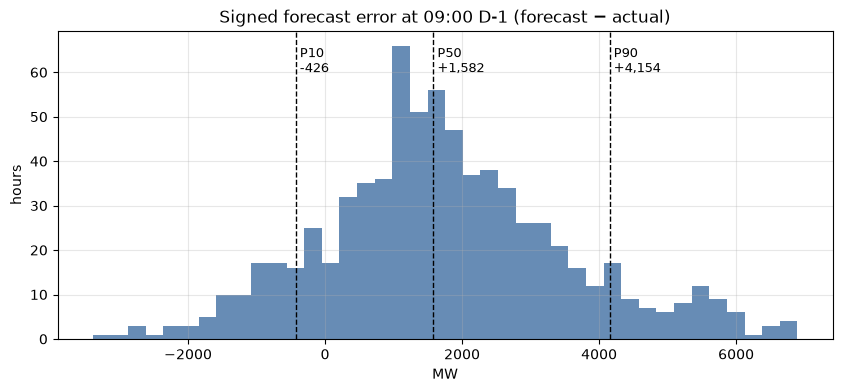

In [5]:
print(f"P90 of |error|: {m['p90_abs']:,.0f} MW  -> in 90% of hours actual is within ±{m['p90_abs']:,.0f} MW of forecast")
print(f"Signed error P10 / P50 / P90: {m['p10']:+,.0f} / {m['p50']:+,.0f} / {m['p90']:+,.0f} MW")
print(f"So 80% of hours fall in [{m['p10']:+,.0f}, {m['p90']:+,.0f}] MW (forecast − actual).")

fig, ax = plt.subplots()
ax.hist(p["error"], bins=40, color="#4c78a8", alpha=0.85)
for q, label in [(m["p10"], "P10"), (m["p50"], "P50"), (m["p90"], "P90")]:
    ax.axvline(q, color="k", ls="--", lw=1)
    ax.text(q, ax.get_ylim()[1] * 0.95, f" {label}\n {q:+,.0f}", va="top", fontsize=9)
ax.set(title="Signed forecast error at 09:00 D-1 (forecast − actual)", xlabel="MW", ylabel="hours")
plt.show()

**Reading:** the error distribution is lopsided. The forecast is too high in most hours, so the risk for
the buyer is almost entirely **shortfall**: actual wind came in below forecast and the gap had to be bought late.
A symmetric ±buffer overstates the risk of having too much power. The cell below separates the systematic offset
from the random part of the error.

In [6]:
debiased = p["error"] - m["bias"]
print(f"Systematic offset (bias): {m['bias']:+,.0f} MW")
print(f"MAE after removing the bias: {debiased.abs().mean():,.0f} MW (was {m['mae']:,.0f})")
print(f"P90 |error| after removing the bias: {debiased.abs().quantile(0.9):,.0f} MW (was {m['p90_abs']:,.0f})")
print(f"One-sided shortfall buffer: actual >= forecast − {m['p90']:,.0f} MW in 90% of hours")

Systematic offset (bias): +1,746 MW
MAE after removing the bias: 1,376 MW (was 2,022)
P90 |error| after removing the bias: 3,115 MW (was 4,154)
One-sided shortfall buffer: actual >= forecast − 4,154 MW in 90% of hours


## 3. How much does error grow with horizon?

At a fixed 09:00 D-1 cutoff every forecast is roughly 15–39 h old, so the first table only covers that range.
To see the full curve, the second part switches to **horizon mode** and sweeps the horizon from 1 h to 48 h.

In [7]:
pd.DataFrame(breakdown(df, "horizon")).set_index("key")

,n,mae,bias,p90_abs
key,,,,
<18 h,62,"2,059.8","1,994.5","4,140.7"
18–24 h,186,"2,344.1","2,273.3","4,970.5"
24–30 h,186,"1,964.7","1,641.6","3,771.5"
30–36 h,186,"1,892.9","1,357.4","3,979.0"
36 h+,124,"1,802.3","1,570.0","4,137.7"


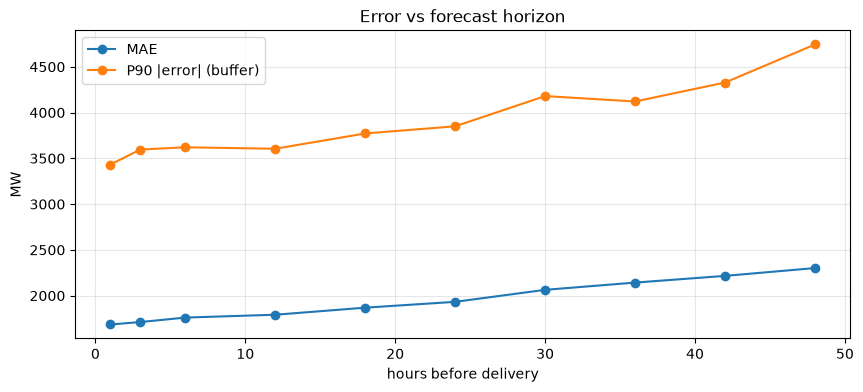

,n,mae,rmse,bias,p90_abs
horizon_h,,,,,
1,744,"1,684.5","2,152.3","1,472.0","3,432.2"
3,744,"1,711.4","2,187.4","1,503.8","3,596.0"
6,744,"1,760.1","2,228.0","1,571.0","3,620.5"
12,744,"1,791.2","2,263.6","1,595.1","3,604.7"
18,744,"1,868.4","2,336.1","1,676.9","3,771.7"
24,744,"1,932.2","2,399.4","1,736.2","3,849.8"
30,744,"2,063.2","2,536.2","1,773.6","4,180.2"
36,744,"2,142.5","2,647.8","1,833.7","4,120.9"
42,744,"2,215.6","2,753.3","1,845.6","4,328.0"


In [8]:
rows = []
for h in [1, 3, 6, 12, 18, 24, 30, 36, 42, 48]:
    s = summary(select_forecasts(ds.actuals, ds.forecasts, Cutoff(mode="horizon", horizon_h=h),
                                 WINDOW_START, WINDOW_END), ds.capacity_mw)
    rows.append({"horizon_h": h, "n": s["n"], "mae": s["mae"], "rmse": s["rmse"], "bias": s["bias"], "p90_abs": s["p90_abs"]})
sweep = pd.DataFrame(rows).set_index("horizon_h")

fig, ax = plt.subplots()
ax.plot(sweep.index, sweep["mae"], marker="o", label="MAE")
ax.plot(sweep.index, sweep["p90_abs"], marker="o", label="P90 |error| (buffer)")
ax.set(title="Error vs forecast horizon", xlabel="hours before delivery", ylabel="MW")
ax.legend()
plt.show()
sweep

In [9]:
growth = sweep.loc[36, "mae"] / sweep.loc[6, "mae"]
print(f"MAE at 36 h is {growth:.1f}x MAE at 6 h ({sweep.loc[6, 'mae']:,.0f} -> {sweep.loc[36, 'mae']:,.0f} MW).")

MAE at 36 h is 1.2x MAE at 6 h (1,760 -> 2,142 MW).


**Reading:** error grows steadily but slowly with horizon (about 1.2× from 6 h to 36 h). The bias barely moves:
it is still about +1,500 MW one hour ahead. That points to a **definitional gap** between the two datasets, not a
forecasting-skill problem. The most likely cause is curtailment: FUELHH is metered output after the system
operator has turned wind farms down, while WINDFOR forecasts what the wind could produce. In the first table,
18–24 h looks worst only because, with a 09:00 cutoff, that bucket holds the overnight delivery hours. Horizon and
time of day are mixed up there; the sweep separates them.

## 4. Which times of day are worst?

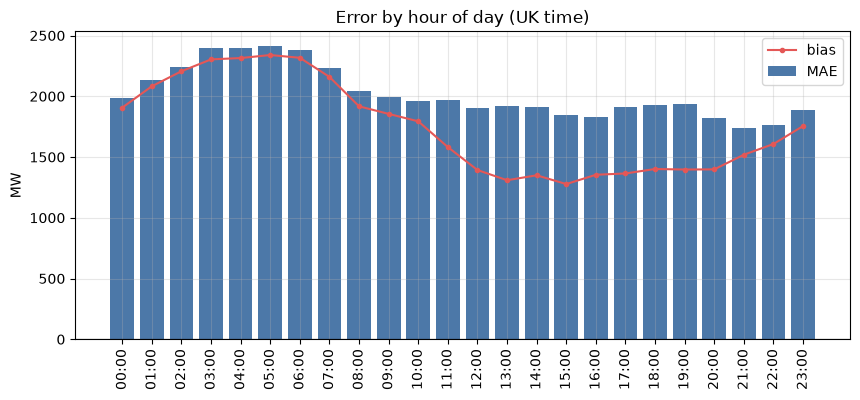

,n,mae,bias,p90_abs
key,,,,
05:00,31,"2,414.2","2,339.4","4,891.0"
04:00,31,"2,394.4","2,314.5","4,611.0"
03:00,31,"2,393.5","2,303.6","4,409.0"
06:00,31,"2,383.2","2,316.7","4,709.0"
02:00,31,"2,242.5","2,205.9","4,255.0"


In [10]:
hours = pd.DataFrame(breakdown(df, "hour")).set_index("key")

fig, ax = plt.subplots()
ax.bar(hours.index, hours["mae"], color="#4c78a8", label="MAE")
ax.plot(hours.index, hours["bias"], color="#e45756", marker=".", label="bias")
ax.axhline(0, color="k", lw=0.8)
ax.set(title="Error by hour of day (UK time)", ylabel="MW")
ax.tick_params(axis="x", rotation=90)
ax.legend()
plt.show()
hours.sort_values("mae", ascending=False).head(5)

## 5. Which days were worst, and were they windy days?

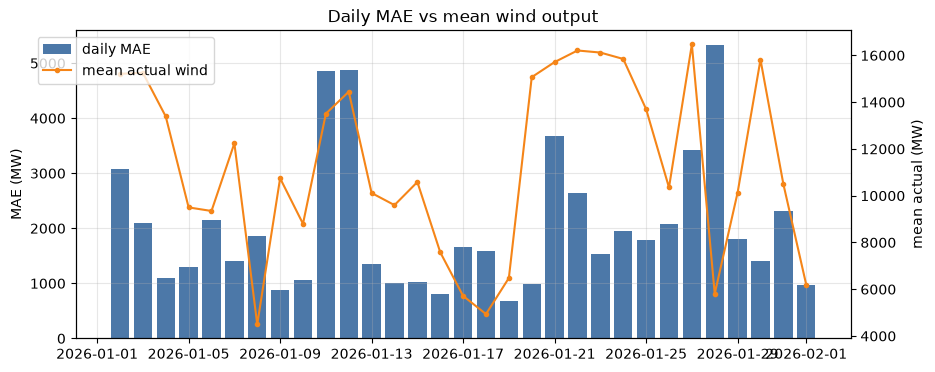

,mae,bias,p90_abs,actual_mean,actual_range
key,,,,,
2026-01-28,"5,329.0","5,329.0","5,949.7","5,805.6","6,624.0"
2026-01-12,"4,875.4","4,875.4","6,718.5","14,445.0","1,636.0"
2026-01-11,"4,853.0","4,853.0","5,774.2","13,506.0","7,769.0"
2026-01-21,"3,677.1","3,677.1","4,679.6","15,712.9","4,812.0"
2026-01-27,"3,418.6","3,418.6","4,095.8","16,469.0","5,851.0"


In [11]:
days = pd.DataFrame(breakdown(df, "day")).set_index("key")
daily_wind = p.groupby(p["local"].dt.strftime("%Y-%m-%d"))["actual"].agg(["mean", "max", "min"])
daily_wind["range"] = daily_wind["max"] - daily_wind["min"]
days = days.join(daily_wind.add_prefix("actual_"))

fig, ax1 = plt.subplots()
ax1.bar(pd.to_datetime(days.index), days["mae"], color="#4c78a8", label="daily MAE")
ax1.set_ylabel("MAE (MW)")
ax2 = ax1.twinx()
ax2.plot(pd.to_datetime(days.index), days["actual_mean"], color="#f58518", marker=".", label="mean actual wind")
ax2.set_ylabel("mean actual (MW)")
ax2.grid(False)
ax1.set_title("Daily MAE vs mean wind output")
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.88))
plt.show()

days.sort_values("mae", ascending=False).head(5)[["mae", "bias", "p90_abs", "actual_mean", "actual_range"]]

In [12]:
print("Correlation of daily MAE with:")
print(f"  mean actual wind  : {days['mae'].corr(days['actual_mean']):+.2f}")
print(f"  intraday range    : {days['mae'].corr(days['actual_range']):+.2f}")
print(f"  |daily bias|      : {days['mae'].corr(days['bias'].abs()):+.2f}")

Correlation of daily MAE with:
  mean actual wind  : +0.25
  intraday range    : -0.00
  |daily bias|      : +0.96


**Reading:** daily MAE tracks the daily bias almost exactly (correlation ≈ 0.96) and has no relationship
with how much output swung during the day. The bad days are days when the forecast sat **above actual all day
long**, not days with badly timed ramps. They are not simply the windiest days either: the worst day, 28 Jan,
was one of the calmest, with mean output about half the monthly average. Before linking any day to a named storm
in the video, check it against the Met Office storm list for winter 2025/26.

## 6. Sensitivity to the decision time on D-1

In [13]:
sens = []
for t in [time(6), time(9), time(12)]:
    s = summary(select_forecasts(ds.actuals, ds.forecasts, Cutoff(decision_time=t), WINDOW_START, WINDOW_END),
                ds.capacity_mw)
    sens.append({"decision": f"{t:%H:%M} D-1", "n": s["n"], "mae": s["mae"], "rmse": s["rmse"],
                 "bias": s["bias"], "p90_abs": s["p90_abs"]})
sens = pd.DataFrame(sens).set_index("decision")
sens

,n,mae,rmse,bias,p90_abs
decision,,,,,
06:00 D-1,744,"2,003.4","2,515.5","1,669.1","4,169.3"
09:00 D-1,744,"2,022.5","2,497.4","1,745.9","4,154.4"
12:00 D-1,744,"1,884.0","2,350.3","1,685.3","3,767.7"


In [14]:
d = sens.loc["06:00 D-1", "mae"] - sens.loc["12:00 D-1", "mae"]
print(f"Deciding at 12:00 instead of 06:00 changes MAE by {-d:+,.0f} MW ({-d / sens.loc['06:00 D-1', 'mae'] * 100:+.1f}%).")

Deciding at 12:00 instead of 06:00 changes MAE by -119 MW (-6.0%).


**Reading:** moving the decision from 06:00 to 09:00 gains nothing, because no newer WINDFOR run lands in
between that changes much. Waiting until 12:00 cuts MAE by about 6% and the 90% buffer by about 400 MW, but 12:00
is after both GB day-ahead auctions close (09:20 and 09:50), so the buyer cannot use it. 09:00 remains the right
default; the cutoff choice matters far less than the bias.

## 7. Cross-check: instant vs hourly-average pairing

WINDFOR gives one value per hour and FUELHH one per half hour. The app pairs each forecast with the actual for
the half hour that starts at the same time. If the forecast is really an hourly average, pairing it with the
mean of the :00 and :30 actuals would score better. This compares the two.

In [15]:
a = ds.actuals.set_index("startTime")["generation"].astype(float)
hourly_mean = a.groupby(a.index.floor("h")).mean()
alt = p[["startTime", "forecast"]].copy()
alt["actual"] = alt["startTime"].map(hourly_mean)
alt_e = alt["forecast"] - alt["actual"]
pd.DataFrame({
    "MAE": [p["error"].abs().mean(), alt_e.abs().mean()],
    "bias": [p["error"].mean(), alt_e.mean()],
    "P90 |e|": [p["error"].abs().quantile(0.9), alt_e.abs().quantile(0.9)],
}, index=["paired with :00 half hour (app)", "paired with hourly mean"])

,MAE,bias,P90 |e|
paired with :00 half hour (app),"2,022.5","1,745.9","4,154.4"
paired with hourly mean,"2,038.9","1,747.9","4,097.9"


**Reading:** both pairings give practically the same numbers (MAE within 1%), so the app's simpler exact
`startTime` join is safe.

## 8. Conclusion (same text the app shows)

In [16]:
print(conclusion(df, default, ds.capacity_mw))

At a 09:00 D-1 decision time, the wind forecast missed actual output by 2,022 MW on average (17.9% of mean output) and tended to over-forecast by 1,746 MW, which means buying too little power. In 90% of hours the error was within ±4,154 MW, so holding a buffer of about that size covers 9 in 10 hours. The forecast was too high in 85% of hours, so the real risk is a shortfall: in 90% of hours actual wind was no more than 4,154 MW below forecast. Errors were largest around 03:00, 04:00, 05:00 UK time and on 28 Jan and 12 Jan; a bigger buffer is justified then.
